# 02 - The Jacobian of a full scan

Notebook 00 built the local Jacobian $A_{\mathbf R}$ at a single probe position and
notebook 01 swept the probe parameters that shape it. This notebook stacks every position
of a scan into the one operator the measurement actually realises, and asks the question
that operator answers:

> *which changes to the specimen would this scan have seen, and which would it have missed
> entirely?*

## The forward model

In a 4D-STEM scan the diffraction pattern recorded at probe position
$\mathbf R = (R_x, R_y)$ is

$$I_{\mathbf R}(\mathbf k) = \left|\mathcal F\left[P(\mathbf r - \mathbf R)\,O(\mathbf r)\right]\right|^2
= \left|\mathcal F\left[P_{\mathbf R} O\right]\right|^2 .$$

A faint excitation perturbs the object in phase only, $O_{\mathrm{on}} = O_0 e^{j\Delta\varphi}$
with $O_0 = T e^{j\varphi_{\mathrm{off}}}$ the base state and $\Delta\varphi$ real. For
$|\Delta\varphi| \ll 1$ radian, $e^{j\Delta\varphi} \approx 1 + j\Delta\varphi$ and the
detector-plane wave separates into a base term and a perturbation term,

$$\Psi_{\mathrm{on},\mathbf R} = \mathcal F\{P_{\mathbf R}O_0\} + j\,\mathcal F\{P_{\mathbf R}O_0\,\Delta\varphi\}
 = \Psi_{0,\mathbf R} + j\Psi_{\Delta,\mathbf R},$$

so the first-order change in the recorded intensity is linear in $\Delta\varphi$:

$$\Delta I_{\mathbf R}(\mathbf k) = -2\,\mathrm{Im}\!\left[\Psi_{0,\mathbf R}^{*}(\mathbf k)\,
\mathcal F\{\psi_{0,\mathbf R}\Delta\varphi\}(\mathbf k)\right] \;=\; \left[A_{\mathbf R}\Delta\varphi\right](\mathbf k).$$

This is the derivative of the *predicted* intensity with respect to the excitation, not a
subtraction of two measured patterns. Nothing below requires light-on and light-off data at
the same probe position.

## Stacking the scan

Stacking the per-position blocks gives the operator of the whole scan,

$$\Delta I_{\mathrm{4D}} = A\,\Delta\varphi,
\qquad
A = \begin{bmatrix} A_{\mathbf R_1} \\ A_{\mathbf R_2} \\ A_{\mathbf R_3} \\ \vdots \end{bmatrix},
\qquad A \in \mathbb R^{SM \times N},$$

with $N$ the number of pixels in $\Delta\varphi$, $M$ the number of pixels in one
diffraction pattern and $S$ the number of scan positions. Here that is
$5\,664\,400 \times 63\,001$ - 1.4 TB in float32, so a direct SVD is out of the question.

Instead take the Gram matrix, which is $N \times N$:

$$A^{\mathsf T}A = (U\Sigma V^{\mathsf T})^{\mathsf T} U\Sigma V^{\mathsf T} = V\Sigma^2 V^{\mathsf T}.$$

Its eigendecomposition gives the right singular vectors of $A$ - **real phase perturbations
in object space** - and the squares of its singular values. Nothing is given up relative to
the SVD, and the matrix to be diagonalized shrinks from $SM \times N$ to the size of the
object. It also decomposes over scan positions,

$$A^{\mathsf T}A = \sum_{\mathbf R} A_{\mathbf R}^{\mathsf T}A_{\mathbf R},$$

so one position's Jacobian need ever be resident at a time, and the stack is never formed.

| symbol | meaning |
|---|---|
| $O_0$ | the base object, a pure phase object on the object grid |
| $\Delta\varphi$, $h$ | a small **real** phase perturbation of it |
| $\mathbf R$ | one scan position; the scan has $S$ of them |
| $P_{\mathbf R}$ | the probe, centred at $\mathbf R$ |
| $\psi_{0,\mathbf R} = P_{\mathbf R}O_0$ | the **exit wave** at that position, on the object grid |
| $\Psi_{0,\mathbf R}$ | the base camera wave, $\mathrm{crop}\,\mathcal F\{\psi_{0,\mathbf R}\}$ |
| $N$, $M$, $S$ | object pixels, detector pixels per pattern, scan positions |
| $\sigma_i$, $v_i$ | singular value and object-space mode $i$ of the stacked $A$ |

A mode $v_i$ produces a detector response of norm $\sigma_i$ per unit norm of perturbation.
So $v_1$ is the perturbation this scan sees *best*, and a mode whose $\sigma$ has collapsed
is one the scan is effectively blind to.

*Notebook 02.5 carries the method checks: a second and a third way of extracting the same
modes, the bounds that relate them, the degeneracy test, and the numerical floors.*

In [1]:
import sys
import time
from pathlib import Path

import numpy as np
import torch
import matplotlib.pyplot as plt

NOTEBOOK_DIR = Path.cwd()
if str(NOTEBOOK_DIR) not in sys.path:
    sys.path.insert(0, str(NOTEBOOK_DIR))

import fft_structured_gram as fsg
import scan_jacobian_utils as sju

torch.backends.cuda.matmul.allow_tf32 = False   # the Gram needs every bit it can get

print("notebook dir :", NOTEBOOK_DIR)
print("torch        :", torch.__version__)
print("cuda device  :", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none")
if torch.cuda.is_available():
    free_bytes, total_bytes = torch.cuda.mem_get_info()
    print("device memory:", f"{total_bytes / 1e9:.1f} GB total, {free_bytes / 1e9:.1f} GB free")

notebook dir : /home/rotem/ptycho_light/quantem/scripts/linearized-ptycho
torch        : 2.14.1+cu130
cuda device  : NVIDIA GeForce RTX 5090
device memory: 33.7 GB total, 1.4 GB free


## Configuration

The only cell to edit per experiment.

`scan_endpoint` matters more than it looks. The simulation cell is periodic, so a scan built
with `endpoint=True` puts its last row and column back on top of its first. Those positions
then enter the stack twice and the corner four times, $A^{\mathsf T}A$ carries that weight,
and the leading modes pile up on the over-counted boundary - which is a property of the scan
bookkeeping, not of the optics. It is left `False`, and the duplicate count is reported below.

In [2]:
config = sju.ExperimentConfig(
    phase_cache_path=NOTEBOOK_DIR.parent / "bcenters_base_excited_phases_wide_fov.pkl",
    phase_cache_key_base="base",
    acc_voltage_ev=60e3,
    probe_semiangle_mrad=30.0,
    probe_defocus_ang=0.0,
    slice_thickness_ang=1.0,            # bookkeeping slice for a projected phase object
    hbn_lattice_constant_ang=2.504,     # annotation and the atom check only
    scan_step_size_ang=0.5,             # requested step; GridScan rounds it to fit the extent
    scan_region_start=(7.0, 7.0),
    scan_region_end=(17.0, 17.0),
    scan_endpoint=False,
    # The Gram below is read from cache, so this notebook only needs room for the waves.
    # Raise min_free_gb to ~30 to rebuild the Gram from scratch on the GPU.
    device=sju.pick_device(min_free_gb=2.0),
)

# --- the Gram, and how many of its modes to extract ------------------------------
# float32 is forced by memory: a float64 Gram on the object grid is 31.8 GB and the
# accumulation needs the Kronecker operator beside it.  Notebook 02.5 shows what that
# costs and where the arithmetic floor lands.
GRAM_PRECISION = "float32"
GRAM_ROW_BLOCK = 4096               # object rows of the Gram updated per GEMM
N_MODES = 1024                      # modes kept
N_OVERSAMPLE = 256                  # extra sketch vectors, discarded after the Ritz step
N_ITERATIONS = 20
USE_CACHE = True                    # reuse a saved spectrum when every input below matches
CACHE_DIR = NOTEBOOK_DIR / "data"

RANDOM_SEED = 0
N_MODES_SHOWN = 6                   # panels in the mode figure

print("device                :", config.device)
print("phase cache           :", Path(config.phase_cache_path).name)
print("requested scan step   :", config.scan_step_size_ang, "A")
print("scan region [A]       :", config.scan_region_start, "to", config.scan_region_end)
print("Gram                  :", GRAM_PRECISION, f"top {N_MODES} modes")

device: cpu   (only 1.4 GB free of 33.7 GB on the GPU, 2.0 GB asked for)
device                : cpu
phase cache           : bcenters_base_excited_phases_wide_fov.pkl
requested scan step   : 0.5 A
scan region [A]       : (7.0, 7.0) to (17.0, 17.0)
Gram                  : float32 top 1024 modes


## The base state, the probe and the scan

Built here from the cached phase so that the probe settings and the scan are parameters of
this notebook rather than properties of a saved file. Only the **base** object enters the
operator - the Jacobian is a derivative evaluated at the base state and never sees the
excitation.

The exit and camera waves are carried in complex128. The inputs themselves are float32
(that is what abTEM returns), so this does not make the *model* more accurate; it means that
the accumulation of $\sum_{\mathbf R}A_{\mathbf R}^{\mathsf T}A_{\mathbf R}$, which is where
digits are actually lost, is not the limiting factor.

In [3]:
experiment = sju.build_experiment(config)
e = experiment            # short alias, used by the figure cells below

print("exit waves                 :", tuple(e.exit_wave_by_scan.shape), e.exit_wave_by_scan.dtype)
print("camera waves               :", tuple(e.camera_wave_by_scan.shape), e.camera_wave_by_scan.dtype)
print("object grid [px]           :", (e.n_object_y, e.n_object_x), f"= {e.n_object_pixels:,} pixels")
print("object sampling [A/px]     :", tuple(round(v, 5) for v in e.object_sampling_ang))
print("field of view [A]          :", tuple(round(v, 3) for v in e.field_of_view_ang))
print("detector [px]              :", e.detector_shape, f"= {e.n_detector_pixels:,} pixels")
print("detector sampling [1/A]    :", tuple(round(v, 5) for v in e.detector_sampling_inv_ang))
print("wavelength [A]             :", round(e.electron_wavelength_ang, 5))
print("scan                       :", e.scan_shape, f"= {e.n_scan_positions} positions "
      f"at {e.realised_scan_step_ang:.3f} A")
print("distinct modulo the cell   :", e.n_distinct_scan_positions,
      "(duplicates:", e.n_scan_positions - e.n_distinct_scan_positions, ")")
print(f"stacked operator A         : {e.stacked_shape[0]:,} x {e.stacked_shape[1]:,}"
      f"   ({4 * e.stacked_shape[0] * e.stacked_shape[1] / 1e12:.1f} TB as float32 - never formed)")
print(f"Gram A^T A                 : {e.n_object_pixels:,} x {e.n_object_pixels:,}"
      f"   ({4 * e.n_object_pixels ** 2 / 1e9:.1f} GB float32,"
      f" {8 * e.n_object_pixels ** 2 / 1e9:.1f} GB float64)")

exit waves                 : (400, 251, 251) torch.complex128
camera waves               : (400, 119, 119) torch.complex128
object grid [px]           : (251, 251) = 63,001 pixels
object sampling [A/px]     : (0.096, 0.096)
field of view [A]          : (24.096, 24.096)
detector [px]              : (119, 119) = 14,161 pixels
detector sampling [1/A]    : (0.0415, 0.0415)
wavelength [A]             : 0.04866
scan                       : (20, 20) = 400 positions at 0.500 A
distinct modulo the cell   : 400 (duplicates: 0 )
stacked operator A         : 5,664,400 x 63,001   (1.4 TB as float32 - never formed)
Gram A^T A                 : 63,001 x 63,001   (15.9 GB float32, 31.8 GB float64)


## The probe and the scan, before anything is read off a spectrum

The whole operator is built from these two things. A mode figure can look structured while
the probe behind it is wrong, and no object-space quantity will say so.

The coverage map $\sum_{\mathbf R}|P_{\mathbf R}|^2$ is how much illumination each object
pixel receives over the whole scan. A focused probe stepped more coarsely than its own width
leaves this ragged, and a ragged coverage map puts structure at the scan period into every
mode. The max/min ratio printed beside the panel is the honest statement of how much of the
spectrum belongs to the sampling rather than to the optics.

The atomic columns are detected from the projected phase, since the cache stores only the
image. If the median spacing of the detected peaks is not the hBN bond length, the peaks are
not the lattice and the overlay would be decoration rather than information - so it is checked.

atomic columns detected    : 219
median nn spacing          : 1.440 A   (hBN bond a/sqrt(3) = 1.446 A, -0.4%)
probe FWHM, measured       : 0.839 A   (ideal Airy 0.51 lambda/alpha : 0.834 A, +0.6%)
scan step                  : 0.500 A  =  0.60 x the probe FWHM
coverage max/min, whole grid : 2060.1


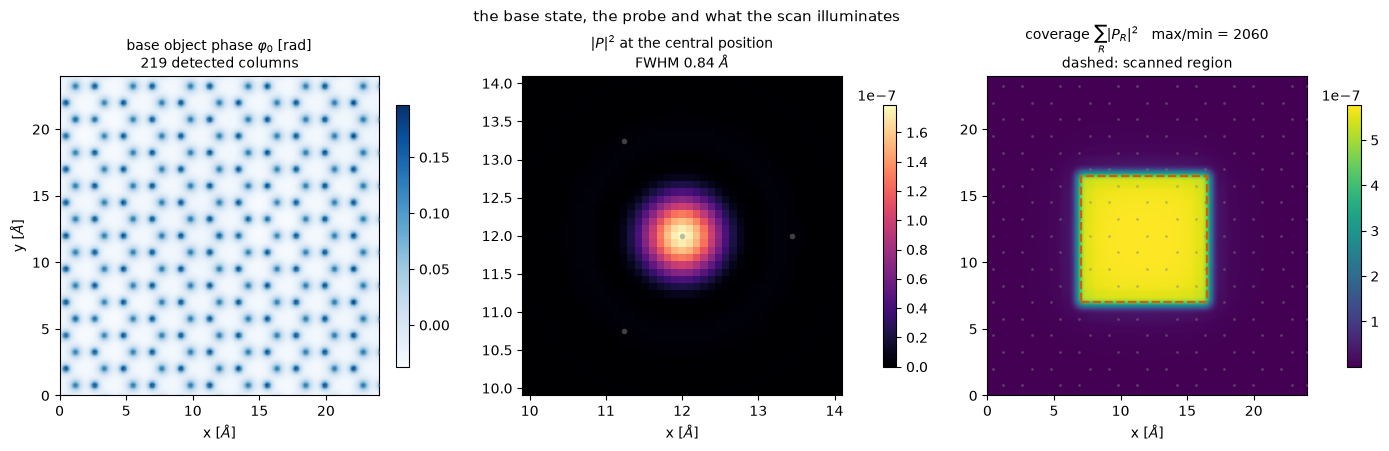

In [4]:
print(f"atomic columns detected    : {len(e.atom_x_ang)}")
print(f"median nn spacing          : {e.atom_nn_spacing_ang:.3f} A"
      f"   (hBN bond a/sqrt(3) = {e.hbn_bond_length_ang:.3f} A,"
      f" {e.atom_nn_spacing_ang / e.hbn_bond_length_ang - 1:+.1%})")
print(f"probe FWHM, measured       : {e.probe_fwhm_ang:.3f} A"
      f"   (ideal Airy 0.51 lambda/alpha : {e.airy_fwhm_ang:.3f} A,"
      f" {e.probe_fwhm_ang / e.airy_fwhm_ang - 1:+.1%})")
print(f"scan step                  : {e.realised_scan_step_ang:.3f} A  =  "
      f"{e.realised_scan_step_ang / e.probe_fwhm_ang:.2f} x the probe FWHM")
print(f"coverage max/min, whole grid : {e.coverage.max() / e.coverage.min():.1f}")

fig, axes = plt.subplots(1, 3, figsize=(14.0, 4.3), constrained_layout=True)

handle = axes[0].imshow(e.phase_base, extent=e.object_extent_ang, origin="lower", cmap="Blues")
sju.draw_atoms_on(axes[0], e)
axes[0].set_title(f"base object phase $\\varphi_0$ [rad]\n{len(e.atom_x_ang)} detected columns",
                  fontsize=10)
fig.colorbar(handle, ax=axes[0], shrink=0.82)

probe_view = 2.5 * e.probe_fwhm_ang
handle = axes[1].imshow(e.probe_centre_intensity, extent=e.object_extent_ang, origin="lower",
                        cmap="magma")
axes[1].set_xlim(e.object_x_ang[e.probe_peak_col] - probe_view,
                 e.object_x_ang[e.probe_peak_col] + probe_view)
axes[1].set_ylim(e.object_y_ang[e.probe_peak_row] - probe_view,
                 e.object_y_ang[e.probe_peak_row] + probe_view)
sju.draw_atoms_on(axes[1], e, markersize=4.0, alpha=0.5)
axes[1].set_title(f"$|P|^2$ at the central position\nFWHM {e.probe_fwhm_ang:.2f} $\\AA$",
                  fontsize=10)
fig.colorbar(handle, ax=axes[1], shrink=0.82)

handle = axes[2].imshow(e.coverage, extent=e.object_extent_ang, origin="lower", cmap="viridis")
sju.draw_atoms_on(axes[2], e)
axes[2].add_patch(plt.Rectangle((e.scan_box_ang[0], e.scan_box_ang[2]),
                                e.scan_box_ang[1] - e.scan_box_ang[0],
                                e.scan_box_ang[3] - e.scan_box_ang[2],
                                fill=False, edgecolor="#D55E00", linewidth=1.6, linestyle="--"))
axes[2].set_title(f"coverage $\\sum_R |P_R|^2$   max/min = {e.coverage.max() / e.coverage.min():.0f}"
                  f"\ndashed: scanned region", fontsize=10)
fig.colorbar(handle, ax=axes[2], shrink=0.82)

for ax in axes:
    ax.set_xlabel("x [$\\AA$]")
axes[0].set_ylabel("y [$\\AA$]")
fig.suptitle("the base state, the probe and what the scan illuminates", fontsize=11)
plt.show()

## Band limits the spectrum has to respect

Three spatial frequencies in the object set what the stacked Jacobian can possibly see: the
**object Nyquist** $1/(2\Delta x)$, the highest the simulation grid carries; the **detector
edge** $q_{\max}$, the highest the camera records; and the **aperture radius**
$\alpha/\lambda$, the probe's own bandwidth.

A phase perturbation at frequency $\mathbf q$ multiplies the exit wave, which convolves the
detector wave with $\Phi(\mathbf q)$ and so shifts the bright-field disc to $\pm\mathbf q$.
It can therefore only reach the camera while

$$|\mathbf q| \lesssim q_{\max} + \alpha/\lambda .$$

Everything above that is in the null space by construction, and the spectra below should show
it. The condition is necessary, not sufficient: the shifted copy also has to land with a
relative phase that survives the $\mathrm{Im}[\cdot]$. The frequency that turns out to matter
most is a *fourth* one, $2\alpha/\lambda$ - the last frequency at which two points of the
bright-field disc still overlap - and it appears on its own in the final figure.

In [5]:
print(f"aperture radius alpha/lambda : {e.aperture_radius_inv_ang:.3f} 1/A")
print(f"2 alpha/lambda               : {2 * e.aperture_radius_inv_ang:.3f} 1/A")
print(f"detector edge q_max          : {e.detector_edge_inv_ang:.3f} 1/A")
print(f"visibility cutoff            : {e.visibility_cutoff_inv_ang:.3f} 1/A"
      "   <- perturbations above this cannot reach the camera")
print(f"object Nyquist               : {e.object_nyquist_inv_ang:.3f} 1/A")
print(f"fraction of the object's frequency square inside the cutoff : "
      f"{np.pi * e.visibility_cutoff_inv_ang ** 2 / (2 * e.object_nyquist_inv_ang) ** 2:.1%}")
print(f"hBN a = {config.hbn_lattice_constant_ang:.3f} A  ->  "
      + ",  ".join(f"{label} at {q:.3f} 1/A (d = {1 / q:.2f} A)"
                   for label, q in e.lattice_reflections_inv_ang))

spectral = sju.SpectralGrid(e)
print(f"\nshared frequency grid : {spectral.radius_inv_ang.shape}"
      f"   d q = {e.detector_sampling_inv_ang[0]:.4f} 1/A,"
      f"  {len(spectral.bin_centres_inv_ang)} radial bins")

aperture radius alpha/lambda : 0.617 1/A
2 alpha/lambda               : 1.233 1/A
detector edge q_max          : 2.449 1/A
visibility cutoff            : 3.065 1/A   <- perturbations above this cannot reach the camera
object Nyquist               : 5.208 1/A
fraction of the object's frequency square inside the cutoff : 27.2%
hBN a = 2.504 A  ->  (10) at 0.461 1/A (d = 2.17 A),  (11) at 0.799 1/A (d = 1.25 A),  (20) at 0.922 1/A (d = 1.08 A),  (21) at 1.220 1/A (d = 0.82 A),  (30) at 1.383 1/A (d = 0.72 A)

shared frequency grid : (251, 251)   d q = 0.0415 1/A,  126 radial bins


---

## Building and diagonalizing the Gram

The Gram is accumulated over the whole object grid and then diagonalized. Its eigenvectors
are the right singular vectors of the stacked $A$ and its eigenvalues are $\sigma_i^2$.

**The work is in constructing it.** At one scan position $A_{\mathbf R}$ is a dense
$M \times N$ matrix - here $14\,161 \times 63\,001$, 3.6 GB in float32 - and the Gram it
contributes is $N \times N$, another 15.9 GB. Neither the stack of all $S$ Jacobians nor a
float64 Gram fits in 32 GB of device memory, so the calculation is split twice. First over
scan positions, $\sum_{\mathbf R}A_{\mathbf R}^{\mathsf T}A_{\mathbf R}$, so only one
position's Jacobian is ever resident and it is overwritten in place by the next. Second,
within each position, the product is accumulated in row blocks of the Gram so the GEMM never
needs a full-size temporary beside its two operands. With both splits the whole calculation
stays on the device.

$A_{\mathbf R}$ itself is built from
$A_{\mathbf R} = -2\,\mathrm{Im}\{D_{\Psi_{0,\mathbf R}^{*}} F D_{\psi_{0,\mathbf R}}\}$:
multiplying by a diagonal matrix on the left scales rows and on the right scales columns, so
only the cropped DFT matrix $F$ has to be built, and it factors into a Kronecker product of
two one-dimensional factors rather than being obtained by transforming an $N \times N$
identity basis.

**Only the top $k$ are extracted.** A complete `eigh` of a $63\,001^2$ matrix needs about six
times the matrix in workspace, some 95 GB, and does not fit. Since the well-measured end is
what the question is about, the top $k = 1024$ eigenpairs are taken by subspace iteration:
apply $G$ to a block of $k + p$ random vectors, re-orthonormalize, repeat, and finish with a
Rayleigh-Ritz step on the small projected matrix. The drift of the Ritz values over the last
iteration is printed, because it is the honest statement of which end has converged.

In [6]:
SOLVER_SETTINGS = (GRAM_PRECISION, GRAM_ROW_BLOCK, N_MODES, N_OVERSAMPLE,
                   N_ITERATIONS, RANDOM_SEED)
cache_path = sju.spectrum_cache_path(CACHE_DIR, e, config, SOLVER_SETTINGS)

gram_real_dtype, gram_complex_dtype = fsg.dtypes_for(GRAM_PRECISION)
gram_rows, gram_cols = fsg.window_indices(e.n_object_y, e.n_object_x, 0)   # 0 = the whole grid

print(f"domain                : the whole object grid, {e.n_object_pixels:,} pixels")
print(f"Gram                  : {e.n_object_pixels:,}^2 "
      f"({(8 if GRAM_PRECISION == 'float64' else 4) * e.n_object_pixels ** 2 / 1e9:.1f} GB"
      f" {GRAM_PRECISION})")
print(f"flops/position        : {2 * e.n_object_pixels ** 2 * e.n_detector_pixels:.2e}")
print(f"cache                 : {cache_path.name}  "
      f"({'present' if cache_path.exists() else 'absent - will rebuild'})")

if not (USE_CACHE and cache_path.exists()) and config.device != "cuda":
    raise RuntimeError(
        f"no cached spectrum at {cache_path.name} and the device is {config.device!r}.\n"
        "Accumulating the Gram needs ~28 GB of device memory; rerun when the GPU is free."
    )

if USE_CACHE and cache_path.exists():
    stored = np.load(cache_path)
    sigma, modes = stored["sigma"], stored["modes"]
    seed_overlap = stored["seed_overlap"]
    ritz_drift = float(stored["drift"])
    build_seconds = float(stored["build_seconds"])
    solve_seconds = float(stored["solve_seconds"])
    peak_gb = float(stored["peak_gb"])
    print(f"\nloaded from {cache_path.name}")
    print(f"   the Gram took {build_seconds:.1f} s and {peak_gb:.1f} GB when this cache "
          f"was written")
else:
    torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats()
    start_time = time.time()
    gram = fsg.dense_gram_accumulate(
        e.exit_wave_by_scan, e.camera_wave_by_scan, gram_rows, gram_cols,
        gram_real_dtype, gram_complex_dtype,
        gram_row_block=GRAM_ROW_BLOCK, rebuild_each_position=True,
        progress_every=max(1, e.n_scan_positions // 8),
    )
    torch.cuda.synchronize()
    build_seconds = time.time() - start_time
    peak_gb = torch.cuda.max_memory_allocated() / 1e9
    print(f"\nGram accumulated in {build_seconds:.1f} s   peak device memory {peak_gb:.1f} GB")

    start_time = time.time()
    sigma, modes, ritz_drift = sju.top_k_eigenpairs(gram, N_MODES, N_OVERSAMPLE,
                                                    N_ITERATIONS, RANDOM_SEED)
    torch.cuda.synchronize()
    solve_seconds = time.time() - start_time

    # fix each mode's sign so its largest-magnitude pixel is positive, as notebook 01 does
    peak_sign = torch.sign(modes.gather(1, modes.abs().argmax(1, keepdim=True)))
    modes = (modes * peak_sign).reshape(N_MODES, e.n_object_y, e.n_object_x)

    # A second, independently seeded run, kept for the degeneracy test in notebook 02.5.
    _, modes_reseeded, _ = sju.top_k_eigenpairs(gram, 64, N_OVERSAMPLE, N_ITERATIONS,
                                               RANDOM_SEED + 1)
    seed_overlap = torch.abs(torch.sum(
        modes.reshape(N_MODES, -1)[:64] * modes_reseeded, dim=1)).cpu().numpy()

    sigma = sigma.cpu().numpy()
    modes = modes.cpu().numpy()
    del gram, modes_reseeded
    torch.cuda.empty_cache()

    CACHE_DIR.mkdir(parents=True, exist_ok=True)
    np.savez(cache_path, sigma=sigma, modes=modes, seed_overlap=seed_overlap, drift=ritz_drift,
             build_seconds=build_seconds, solve_seconds=solve_seconds, peak_gb=peak_gb)
    print(f"saved to {cache_path.name} ({cache_path.stat().st_size / 1e6:.0f} MB)")

qbar = spectral.mode_mean_frequency(modes)
gap = sju.relative_gap(sigma)

print(f"\ntop-{N_MODES} subspace iteration in {solve_seconds:.1f} s "
      f"({N_ITERATIONS} iterations, {N_OVERSAMPLE} oversampled)")
print(f"Ritz drift over the last iteration : {ritz_drift:.2e} x sigma_1")
print(f"sigma_1                            : {sigma[0]:.6e}")
print(f"sigma_{N_MODES}/sigma_1                  : {sigma[-1] / sigma[0]:.4f}")

domain                : the whole object grid, 63,001 pixels
Gram                  : 63,001^2 (15.9 GB float32)
flops/position        : 1.12e+14
cache                 : dense_full_field_spectrum_5454b530a4bda2b6.npz  (present)

loaded from dense_full_field_spectrum_5454b530a4bda2b6.npz
   the Gram took 699.8 s and 27.9 GB when this cache was written



top-1024 subspace iteration in 5.4 s (20 iterations, 256 oversampled)
Ritz drift over the last iteration : 3.22e-06 x sigma_1
sigma_1                            : 6.510881e-03
sigma_1024/sigma_1                  : 0.0669


## The leading modes

The perturbations this scan responds to most strongly, as images on the object grid. Each
panel carries its $\sigma_i/\sigma_1$, the relative gap to the next mode, and its mean
spatial frequency $\bar q_i$.

The gap is printed because a mode picture is only worth reading if the mode is separated from
its neighbours: where a cluster of singular values is exactly degenerate, any orthogonal basis
of the cluster is equally valid and the individual pictures carry no information. Whether that
is the case here is *measured* rather than assumed - the same iteration is run from a second
independent seed and the two mode sets compared, which is the test notebook 02.5 reports. The
one-line answer is printed below the figure.

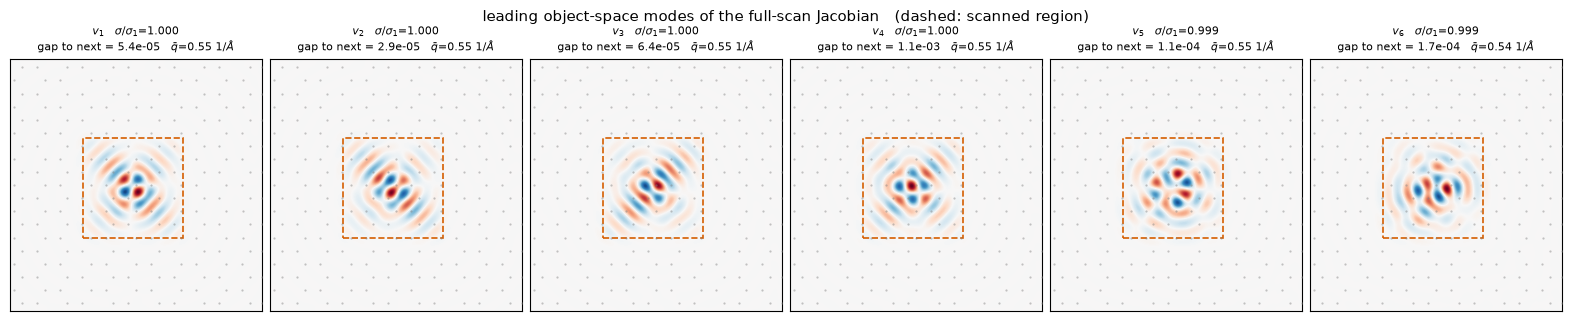

agreement of the first 64 modes with an independently seeded run:
   |<v_i(seed 0), v_i(seed 1)>|  median 1.000, min 1.000, max 1.000
   (1 = the vector itself is well defined; near 0 = only the subspace is)


In [7]:
fig, axes = plt.subplots(1, N_MODES_SHOWN, figsize=(2.6 * N_MODES_SHOWN, 3.2),
                         constrained_layout=True)
limit = float(np.abs(modes[:N_MODES_SHOWN]).max())
for column in range(N_MODES_SHOWN):
    ax = axes[column]
    ax.imshow(modes[column], extent=e.object_extent_ang, origin="lower", cmap="RdBu_r",
              vmin=-limit, vmax=limit, interpolation="nearest")
    sju.draw_atoms_on(ax, e, markersize=1.6)
    ax.add_patch(plt.Rectangle(
        (e.scan_box_ang[0], e.scan_box_ang[2]),
        e.scan_box_ang[1] - e.scan_box_ang[0], e.scan_box_ang[3] - e.scan_box_ang[2],
        fill=False, edgecolor="#D55E00", linewidth=1.2, linestyle="--"))
    ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(f"$v_{{{column + 1}}}$   $\\sigma/\\sigma_1$={sigma[column] / sigma[0]:.3f}\n"
                 f"gap to next = {gap[column]:.1e}   $\\bar q$={qbar[column]:.2f} 1/$\\AA$",
                 fontsize=8)
fig.suptitle("leading object-space modes of the full-scan Jacobian"
             "   (dashed: scanned region)", fontsize=11)
plt.show()

print(f"agreement of the first {len(seed_overlap)} modes with an independently seeded run:")
print(f"   |<v_i(seed 0), v_i(seed 1)>|  median {np.median(seed_overlap):.3f}, "
      f"min {seed_overlap.min():.3f}, max {seed_overlap.max():.3f}")
print("   (1 = the vector itself is well defined; near 0 = only the subspace is)")

## The spectrum, and what kind of perturbation each mode is

A singular value on its own does not say what sort of perturbation it belongs to. Reducing
each mode to its mean spatial frequency,

$$\bar q_i = \frac{\sum_{\mathbf q}|\hat v_i(\mathbf q)|^2\,|\mathbf q|}
{\sum_{\mathbf q}|\hat v_i(\mathbf q)|^2},$$

and plotting it against $\sigma_i/\sigma_1$ turns the spectrum into a statement about *which*
perturbations the scan is blind to, rather than merely how many.

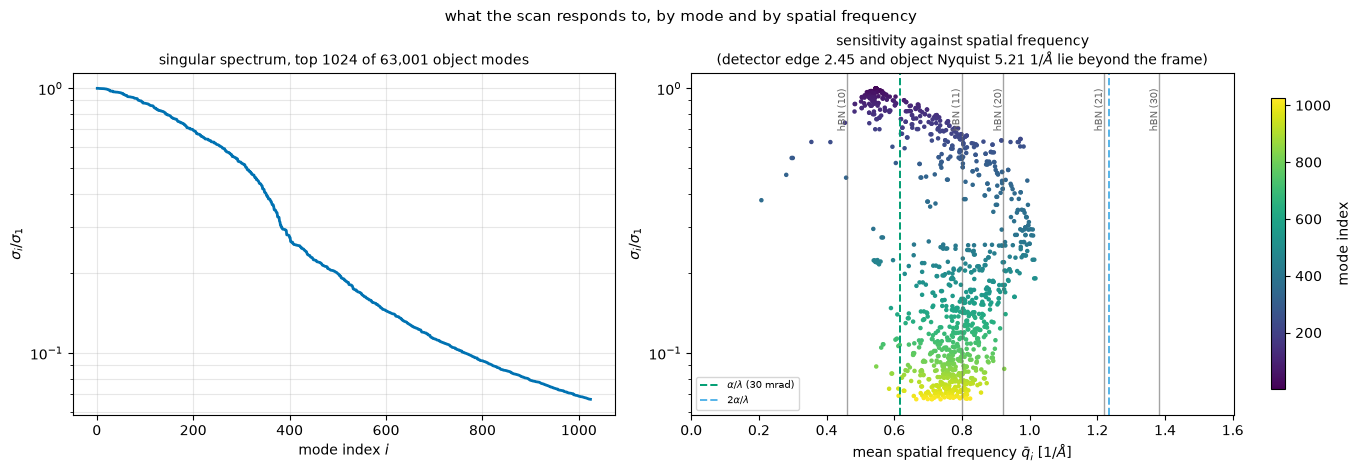

qbar of the leading mode   : 0.546 1/A   (alpha/lambda = 0.617)
qbar range over the top 1024: 0.207 - 1.017 1/A


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.6), constrained_layout=True)
mode_index = np.arange(1, len(sigma) + 1)

axes[0].semilogy(mode_index, sigma / sigma[0], color="#0072B2", linewidth=2.0)
axes[0].set_xlabel("mode index $i$")
axes[0].set_ylabel("$\\sigma_i/\\sigma_1$")
axes[0].set_title(f"singular spectrum, top {len(sigma)} of {e.n_object_pixels:,} object modes",
                  fontsize=10)
axes[0].grid(alpha=0.3, which="both")

handle = axes[1].scatter(qbar, sigma / sigma[0], c=mode_index, cmap="viridis", s=5.0)
axes[1].set_yscale("log")
# The frame stops just past 2 alpha/lambda: every mode lies well inside it, and the
# detector edge (2.449) and object Nyquist (5.208) would otherwise leave the panel
# four-fifths empty.  Both are printed above and drawn in the D(q) figure below.
qbar_view = 2.0 * e.aperture_radius_inv_ang * 1.3
for frequency, label, colour in [
    (e.aperture_radius_inv_ang,
     f"$\\alpha/\\lambda$ ({config.probe_semiangle_mrad:.0f} mrad)", "#009E73"),
    (2 * e.aperture_radius_inv_ang, "$2\\alpha/\\lambda$", "#56B4E9"),
]:
    axes[1].axvline(frequency, color=colour, linestyle="--", linewidth=1.4, label=label)
for label, frequency in e.lattice_reflections_inv_ang:
    if frequency > qbar_view:
        continue
    axes[1].axvline(frequency, color="#666666", linestyle="-", linewidth=1.0, alpha=0.6)
    axes[1].annotate(f"hBN {label}", (frequency, 1.0), rotation=90, fontsize=7,
                     ha="right", va="top", color="#666666")
axes[1].set_xlabel("mean spatial frequency $\\bar q_i$ [1/$\\AA$]")
axes[1].set_ylabel("$\\sigma_i/\\sigma_1$")
axes[1].set_title("sensitivity against spatial frequency\n"
                  f"(detector edge {e.detector_edge_inv_ang:.2f} and object Nyquist "
                  f"{e.object_nyquist_inv_ang:.2f} 1/$\\AA$ lie beyond the frame)", fontsize=10)
axes[1].set_xlim(0, qbar_view)
axes[1].legend(fontsize=7, loc="lower left")
fig.colorbar(handle, ax=axes[1], label="mode index", shrink=0.85)
fig.suptitle("what the scan responds to, by mode and by spatial frequency", fontsize=11)
plt.show()

print(f"qbar of the leading mode   : {qbar[0]:.3f} 1/A"
      f"   (alpha/lambda = {e.aperture_radius_inv_ang:.3f})")
print(f"qbar range over the top {len(sigma)}: {qbar.min():.3f} - {qbar.max():.3f} 1/A")

## Sensitivity per spatial frequency

The mode scatter answers the question one mode at a time. The quantity that answers it for
the *measurement* is fixed by what $A$ does to a plane wave:

$$D(\mathbf q) = \sum_i \sigma_i^2\,|\hat v_i(\mathbf q)|^2
  = \bigl\| A\,f_{\mathbf q} \bigr\|^2, \qquad
  f_{\mathbf q}(\mathbf r) = N^{-1/2} e^{2\pi i \mathbf q\cdot\mathbf r},$$

the squared detector response to a unit-amplitude phase ripple at $\mathbf q$. Three
properties make it the right summary:

* **There is no threshold in it.** Modes near the blind end enter with weight
  $\sigma_i^2 \to 0$ rather than with weight one, so there is nothing to choose and no
  cut to defend.
* **Truncation is one-sided.** Every term is positive, so $D_k \le D$ everywhere and
  monotonically in $k$. Notebook 02.5 measures what the $k = 1024$ cap actually costs.
* **The total is conserved.** $\sum_{\mathbf q} D(\mathbf q) = \|A\|_F^2 = \sum_i\sigma_i^2$,
  so $D$ is a distribution and its angular integral reads as a sensitivity budget over
  $|\mathbf q|$ rather than as an arbitrary-scale curve.

For a dose or detectability argument it is $D$ that enters.

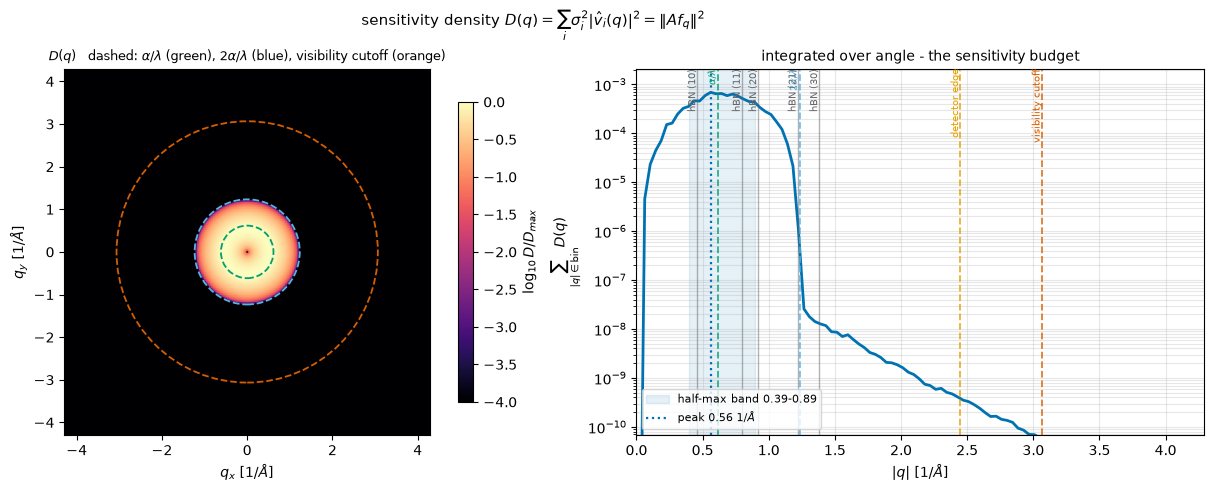

peak of the angular integral      : 0.560 1/A
half-maximum band                 : 0.394 - 0.892 1/A
fraction of the budget below alpha/lambda = 0.617 : 45.5%
sum D(q) over the top 1024 modes  : 9.281746e-03   (= sum sigma_i^2 = 9.281744e-03)
   this is a lower bound on ||A||_F^2, not ||A||_F^2 itself: the modes beyond the
   k = 1024 cap are missing from it.  Notebook 02.5 measures what the cap costs.


In [9]:
density = spectral.sensitivity_density(modes, sigma)
density_radial = spectral.angular_integral(density)
peak_q, band_low, band_high = sju.half_power_band(density_radial, spectral.bin_centres_inv_ang)
inside_aperture = spectral.bin_centres_inv_ang <= e.aperture_radius_inv_ang
fraction_below_aperture = float(density_radial[inside_aperture].sum() / density_radial.sum())

view = e.visibility_cutoff_inv_ang * 1.4
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8), constrained_layout=True)

shown = np.log10(np.maximum(density / density.max(), 1e-6))
handle = axes[0].imshow(shown, extent=spectral.extent, origin="lower", cmap="magma",
                        vmin=-4.0, vmax=0.0)
for frequency, colour in [(e.aperture_radius_inv_ang, "#009E73"),
                          (2 * e.aperture_radius_inv_ang, "#56B4E9"),
                          (e.visibility_cutoff_inv_ang, "#D55E00")]:
    axes[0].add_patch(plt.Circle((0, 0), frequency, fill=False, edgecolor=colour,
                                 linewidth=1.3, linestyle="--"))
axes[0].set_xlim(-view, view); axes[0].set_ylim(-view, view)
axes[0].set_xlabel("$q_x$ [1/$\\AA$]"); axes[0].set_ylabel("$q_y$ [1/$\\AA$]")
axes[0].set_title("$D(q)$   dashed: $\\alpha/\\lambda$ (green), $2\\alpha/\\lambda$ (blue),"
                  " visibility cutoff (orange)", fontsize=9)
fig.colorbar(handle, ax=axes[0], shrink=0.82, label="$\\log_{10} D/D_{max}$")

axes[1].semilogy(spectral.bin_centres_inv_ang, density_radial, color="#0072B2",
                 linewidth=2.0)
axes[1].set_ylim(density_radial.max() * 1e-7, density_radial.max() * 3)
axes[1].axvspan(band_low, band_high, color="#0072B2", alpha=0.10,
                label=f"half-max band {band_low:.2f}-{band_high:.2f}")
axes[1].axvline(peak_q, color="#0072B2", linestyle=":", linewidth=1.6,
                label=f"peak {peak_q:.2f} 1/$\\AA$")
for frequency, colour, label in [
    (e.aperture_radius_inv_ang, "#009E73", "$\\alpha/\\lambda$"),
    (2 * e.aperture_radius_inv_ang, "#56B4E9", "$2\\alpha/\\lambda$"),
    (e.detector_edge_inv_ang, "#E69F00", "detector edge"),
    (e.visibility_cutoff_inv_ang, "#D55E00", "visibility cutoff"),
]:
    axes[1].axvline(frequency, color=colour, linestyle="--", linewidth=1.3, alpha=0.8)
    axes[1].annotate(label, (frequency, axes[1].get_ylim()[1]), rotation=90, fontsize=7,
                     ha="right", va="top", color=colour)
for label, frequency in e.lattice_reflections_inv_ang:
    if frequency > view:
        continue
    axes[1].axvline(frequency, color="#666666", linestyle="-", linewidth=1.0, alpha=0.5)
    axes[1].annotate(f"hBN {label}", (frequency, axes[1].get_ylim()[1]), rotation=90,
                     fontsize=7, ha="right", va="top", color="#666666")
axes[1].set_xlim(0, view)
axes[1].set_xlabel("$|q|$ [1/$\\AA$]")
axes[1].set_ylabel("$\\sum_{|q| \\in \\mathrm{bin}} D(q)$")
axes[1].set_title("integrated over angle - the sensitivity budget", fontsize=10)
axes[1].legend(fontsize=8, loc="lower left"); axes[1].grid(alpha=0.3, which="both")

fig.suptitle("sensitivity density $D(q) = \\sum_i \\sigma_i^2 |\\hat v_i(q)|^2 = \\|Af_q\\|^2$",
             fontsize=11)
plt.show()

print(f"peak of the angular integral      : {peak_q:.3f} 1/A")
print(f"half-maximum band                 : {band_low:.3f} - {band_high:.3f} 1/A")
print(f"fraction of the budget below alpha/lambda = {e.aperture_radius_inv_ang:.3f} : "
      f"{fraction_below_aperture:.1%}")
print(f"sum D(q) over the top {len(sigma)} modes  : {density.sum():.6e}"
      f"   (= sum sigma_i^2 = {float((sigma.astype(np.float64) ** 2).sum()):.6e})")
print("   this is a lower bound on ||A||_F^2, not ||A||_F^2 itself: the modes beyond the\n"
      f"   k = {len(sigma)} cap are missing from it.  Notebook 02.5 measures what the cap costs.")

## How to read this

* **The spectrum has two blind ends, not one.** A spatially constant phase is exactly null -
  for constant $\Delta\varphi$ the perturbation wave is $\Psi_\Delta = \Delta\varphi\,\Psi_0$
  and $\mathrm{Im}(\Delta\varphi|\Psi_0|^2) = 0$ - and so is everything above the visibility
  cutoff. The scan is a **band-pass on object phase**, and its pass band is what any
  reconstruction from this geometry can contain.

* **Sensitivity peaks near the aperture frequency, not at zero.** The leading modes sit at
  $\bar q \sim \alpha/\lambda$ rather than at low frequency, because that is where the
  scattered wave interferes with the bright-field disc over the largest area. This is the
  standard ptychographic transfer argument arriving as a property of the operator rather than
  as an assumption about it.

* **The cliff is optical, not crystallographic.** $D(q)$ falls off at $2\alpha/\lambda$: the
  largest spatial frequency at which two points of the bright-field disc still overlap, and so
  the last frequency that can interfere onto the camera at all. The hBN $(21)$ reflection sits
  within $1\%$ of it, and a plot carrying only the lattice annotation invites exactly the wrong
  reading - which is why the $2\alpha/\lambda$ line is drawn. The position is a property of the
  aperture, and the way to confirm it is to change $\alpha$ and watch the cliff move, which is
  what notebook 01's sweep does.

* **The scan's own bookkeeping is part of the operator.** Duplicate positions and uneven
  coverage both re-weight $A^{\mathsf T}A$, and the leading modes report that weighting before
  they report anything about the optics. The coverage panel is there to be checked first.

### What this does not establish

Every singular value here describes a *noiseless* measurement: the small ones are the
directions a perfect detector could not separate. Adding Poisson noise at a finite dose raises
the effective floor far above the numerical one, so the practically blind subspace is much
larger than the null space of $A$. Turning this spectrum into a statement about what a real
experiment can detect needs the dose and the noise covariance - the conditional Fisher
information $A^{\mathsf T}\Sigma^{-1}A$ rather than $A^{\mathsf T}A$ - and, beyond that, the
nuisance parameters of the base state, which remove from the identifiable subspace anything a
correction to the object, probe or scan positions could imitate. Both belong in their own
notebook.

**Notebook 02.5** carries the methodological checks this one asserts: the windowed and
matrix-free routes to the same modes, the bounds that relate the three, the degeneracy and
seed-reproducibility test, what the $k$ cap costs, and the numerical floors.